### Contents
- [Let's download the necessary Python libraries](#Lets-download-the-necessary-Python-libraries)
- [Getting the data](#Getting-the-data)
- [Exploratory Data Analysis (EDA)](#Exploratory-data-analysis-EDA)
- [Feature Engineering](#Feature-Engineering)
- [Train-Test data split](#Train-Test-data-split)
- [Modelling(s)](#Modellings)
  - [Linear Regression](#Linear-Regression)
  - [Random Forest Regression](#Random-Forest-Regression)
  - [XGBoosting Regression](#XGBoosting-Regression)
- [Model Comparison](#Model-Comparison)
- [Prediction using test data](#Prediction-using-test-data)

#### Let's download the necessary Python libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk 
import statsmodels as sm
import sqlite3

#### Getting the data 

In [2]:
features= pd.read_csv("features.csv") 
stores= pd.read_csv("stores.csv")
train= pd.read_csv("train.csv")
test= pd.read_csv("test.csv")

In [3]:
# SQL variable

conn= sqlite3.connect('walmart.db')

In [4]:
features.to_sql("features",conn, if_exists="replace",index=False)
stores.to_sql("stores", conn, if_exists="replace", index=False)
train.to_sql("train", conn, if_exists="replace", index=False)
test.to_sql("test", conn, if_exists="replace", index=False)

115064

In [5]:
# Combining the data using a LEFT JOIN in SQL and assigning it to a DataFrame.

query = """
SELECT t.*, s.Type, s.Size, f.Temperature, f.CPI, f.Unemployment
FROM train AS t
LEFT JOIN stores s ON t.Store = s.Store
LEFT JOIN features f ON t.Store = f.Store AND t.Date = f.Date;
"""

df0 = pd.read_sql(query, conn)
df0.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106


#### Exploratory data analysis (EDA)

In [6]:
df0.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  int64  
 5   Type          421570 non-null  str    
 6   Size          421570 non-null  int64  
 7   Temperature   421570 non-null  float64
 8   CPI           421570 non-null  float64
 9   Unemployment  421570 non-null  float64
dtypes: float64(4), int64(4), str(2)
memory usage: 32.2 MB


In [7]:
df0.describe()

,Store,Dept,Weekly_Sales,IsHoliday,Size,Temperature,CPI,Unemployment
count,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123,0.070358,136727.915739,60.090059,171.201947,7.960289
std,12.785297,30.492054,22711.183519,0.255750,60980.583328,18.447931,39.159276,1.863296
min,1.000000,1.000000,-4988.940000,0.000000,34875.000000,-2.060000,126.064000,3.879000
25%,11.000000,18.000000,2079.650000,0.000000,93638.000000,46.680000,132.022667,6.891000
50%,22.000000,37.000000,7612.030000,0.000000,140167.000000,62.090000,182.318780,7.866000
75%,33.000000,74.000000,20205.852500,0.000000,202505.000000,74.280000,212.416993,8.572000
max,45.000000,99.000000,693099.360000,1.000000,219622.000000,100.140000,227.232807,14.313000


In [8]:
raw_features = pd.read_sql("SELECT * FROM features", conn)
print(raw_features.isna().sum())

Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64


In [9]:
markdown_cols= ["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]
raw_features[markdown_cols]=raw_features[markdown_cols].fillna(0) 
raw_features.isna().sum()

Store             0
Date              0
Temperature       0
Fuel_Price        0
MarkDown1         0
MarkDown2         0
MarkDown3         0
MarkDown4         0
MarkDown5         0
CPI             585
Unemployment    585
IsHoliday         0
dtype: int64

In [10]:
query = """
SELECT t.*, s.Type, s.Size, 
       f.Temperature, f.CPI, f.Unemployment,
       f.MarkDown1, f.MarkDown2, f.MarkDown3, f.MarkDown4, f.MarkDown5
FROM train AS t
LEFT JOIN stores AS s ON t.Store = s.Store
LEFT JOIN features AS f ON t.Store = f.Store AND t.Date = f.Date;
"""
df = pd.read_sql(query, conn)
df[["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]] = df[["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]].fillna(0)

In [11]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106,0.0,0.0,0.0,0.0,0.0
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106,0.0,0.0,0.0,0.0,0.0
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106,0.0,0.0,0.0,0.0,0.0
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106,0.0,0.0,0.0,0.0,0.0
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106,0.0,0.0,0.0,0.0,0.0


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  int64  
 5   Type          421570 non-null  str    
 6   Size          421570 non-null  int64  
 7   Temperature   421570 non-null  float64
 8   CPI           421570 non-null  float64
 9   Unemployment  421570 non-null  float64
 10  MarkDown1     421570 non-null  float64
 11  MarkDown2     421570 non-null  float64
 12  MarkDown3     421570 non-null  float64
 13  MarkDown4     421570 non-null  float64
 14  MarkDown5     421570 non-null  float64
dtypes: float64(9), int64(4), str(2)
memory usage: 48.2 MB


In [13]:
negative_sales = df[df["Weekly_Sales"] < 0]
print(negative_sales[["Store", "Dept", "Date", "Weekly_Sales"]].sort_values("Weekly_Sales").head(10))
print(negative_sales.shape)

        Store  Dept        Date  Weekly_Sales
267730     28     6  2010-10-08      -4988.94
336495     35    47  2011-09-02      -3924.00
417801     45    47  2010-02-26      -1750.00
153916     16    47  2012-03-09      -1699.00
271300     28    32  2011-03-25      -1321.48
16291       2    47  2010-07-30      -1098.00
16295       2    47  2010-10-15      -1098.00
16297       2    47  2010-11-19      -1098.00
24830       3    32  2011-09-30      -1008.96
35561       4    47  2010-09-17       -898.00
(1285, 15)


In [14]:
df["Weekly_Sales"] = df["Weekly_Sales"].clip(lower=0)
print((df["Weekly_Sales"] < 0).sum()) 


0


In [15]:
df["Date"]=pd.to_datetime(df["Date"],format= "%Y-%m-%d", errors="coerce")
df["IsHoliday"]=df["IsHoliday"].astype("category")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[us]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  category      
 5   Type          421570 non-null  str           
 6   Size          421570 non-null  int64         
 7   Temperature   421570 non-null  float64       
 8   CPI           421570 non-null  float64       
 9   Unemployment  421570 non-null  float64       
 10  MarkDown1     421570 non-null  float64       
 11  MarkDown2     421570 non-null  float64       
 12  MarkDown3     421570 non-null  float64       
 13  MarkDown4     421570 non-null  float64       
 14  MarkDown5     421570 non-null  float64       
dtypes: category(1), datetime64[u

#### Feature Engineering

In [16]:
df.head() 

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106,0.0,0.0,0.0,0.0,0.0
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106,0.0,0.0,0.0,0.0,0.0
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106,0.0,0.0,0.0,0.0,0.0
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106,0.0,0.0,0.0,0.0,0.0
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106,0.0,0.0,0.0,0.0,0.0


In [17]:
df["Year"]= df["Date"].dt.year
df["Month"]= df["Date"].dt.month 
df["WeekOfYear"]= df["Date"].dt.isocalendar().week


In [18]:
conditions= [
    df["Month"].isin([12,1,2]),
    df["Month"].isin([3,4,5]),
    df["Month"].isin([6,7,8]),
]

choices= ["Winter","Spring","Summer"]

df["Session"]= np.select(conditions,choices,default="Fall")
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,Year,Month,WeekOfYear,Session
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106,0.0,0.0,0.0,0.0,0.0,2010,2,5,Winter
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106,0.0,0.0,0.0,0.0,0.0,2010,2,6,Winter
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106,0.0,0.0,0.0,0.0,0.0,2010,2,7,Winter
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106,0.0,0.0,0.0,0.0,0.0,2010,2,8,Winter
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106,0.0,0.0,0.0,0.0,0.0,2010,3,9,Spring


In [19]:
df_sorted= df.sort_values(by="Date")
df["lag_1"]= df_sorted.groupby(["Store","Dept"])["Weekly_Sales"].shift(1)
df["lag_4"]=df_sorted.groupby(["Store","Dept"])["Weekly_Sales"].shift(4)
df["lag_52"]= df_sorted.groupby(["Store","Dept"])["Weekly_Sales"].shift(52)


In [20]:
df.isna().sum()

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Type                 0
Size                 0
Temperature          0
CPI                  0
Unemployment         0
MarkDown1            0
MarkDown2            0
MarkDown3            0
MarkDown4            0
MarkDown5            0
Year                 0
Month                0
WeekOfYear           0
Session              0
lag_1             3331
lag_4            13134
lag_52          160487
dtype: int64

In [21]:

df["lag_1"]=df["lag_1"].fillna(0)
df["lag_4"]=df["lag_4"].fillna(0)
df["lag_52"]= df["lag_52"].fillna(0)


df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,...,MarkDown3,MarkDown4,MarkDown5,Year,Month,WeekOfYear,Session,lag_1,lag_4,lag_52
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106,...,0.0,0.0,0.0,2010,2,5,Winter,0.00,0.0,0.0
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106,...,0.0,0.0,0.0,2010,2,6,Winter,24924.50,0.0,0.0
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106,...,0.0,0.0,0.0,2010,2,7,Winter,46039.49,0.0,0.0
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106,...,0.0,0.0,0.0,2010,2,8,Winter,41595.55,0.0,0.0
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106,...,0.0,0.0,0.0,2010,3,9,Spring,19403.54,24924.5,0.0


In [22]:
df[["lag_1","lag_4","lag_52"]].isna().sum()

lag_1     0
lag_4     0
lag_52    0
dtype: int64

In [23]:
df_sorted= df.sort_values(by="Date")
df["IsBeforeHoliday"]= df_sorted.groupby(["Store","Dept"])["IsHoliday"].shift(-1)
df["IsBeforeHoliday"]=df["IsBeforeHoliday"].fillna(0)

In [24]:
df["IsBeforeHoliday"].isna().sum()

np.int64(0)

In [25]:
print(df["IsBeforeHoliday"].value_counts())
print(df["IsHoliday"].value_counts())

IsBeforeHoliday
0    391995
1     29575
Name: count, dtype: int64
IsHoliday
0    391909
1     29661
Name: count, dtype: int64


In [26]:
print(df.groupby("IsBeforeHoliday")["Weekly_Sales"].mean())
print(df.groupby("IsHoliday")["Weekly_Sales"].mean())

IsBeforeHoliday
0    15832.069128
1    17961.630125
Name: Weekly_Sales, dtype: float64
IsHoliday
0    15901.649652
1    17036.092349
Name: Weekly_Sales, dtype: float64


In [27]:
not_holiday= df.loc[(df["IsHoliday"]==0) & (df["IsBeforeHoliday"]==0)]
not_holiday["Weekly_Sales"].mean()

np.float64(15732.646159004731)

In [28]:
df_sorted= df.sort_values(by="Date")
df["IsAfterHoliday"]= df_sorted.groupby(["Store","Dept"])["IsHoliday"].shift(1)
df["IsAfterHoliday"]=df["IsAfterHoliday"].fillna(0)
print(df.groupby("IsAfterHoliday")["Weekly_Sales"].mean())
print(df["IsAfterHoliday"].value_counts()) 

# Maybe???

IsAfterHoliday
0    16002.546100
1    15702.690833
Name: Weekly_Sales, dtype: float64
IsAfterHoliday
0    391935
1     29635
Name: count, dtype: int64


In [29]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,...,MarkDown5,Year,Month,WeekOfYear,Session,lag_1,lag_4,lag_52,IsBeforeHoliday,IsAfterHoliday
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106,...,0.0,2010,2,5,Winter,0.00,0.0,0.0,1,0
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106,...,0.0,2010,2,6,Winter,24924.50,0.0,0.0,0,0
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106,...,0.0,2010,2,7,Winter,46039.49,0.0,0.0,0,1
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106,...,0.0,2010,2,8,Winter,41595.55,0.0,0.0,0,0
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106,...,0.0,2010,3,9,Spring,19403.54,24924.5,0.0,0,0


#### Train-Test data split

In [30]:
df_encoded= pd.get_dummies(df, columns=["Type","Session"], dtype=int, prefix=["type_","session_"])

In [31]:
df_encoded.columns

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Size',
       'Temperature', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2',
       'MarkDown3', 'MarkDown4', 'MarkDown5', 'Year', 'Month', 'WeekOfYear',
       'lag_1', 'lag_4', 'lag_52', 'IsBeforeHoliday', 'IsAfterHoliday',
       'type__A', 'type__B', 'type__C', 'session__Fall', 'session__Spring',
       'session__Summer', 'session__Winter'],
      dtype='str')

In [32]:
df_encoded= df_encoded.sort_values(by="Date")

In [33]:
from sklearn.model_selection import train_test_split 

X= df_encoded[['Store', 'Dept','IsHoliday', 'Size',
       'Temperature', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2',
       'MarkDown3', 'MarkDown4', 'MarkDown5', 'Year', 'Month', 'WeekOfYear',
        'lag_1','lag_4', 'lag_52', 'IsBeforeHoliday',
       'IsAfterHoliday', 'type__A', 'type__B', 'type__C','session__Fall', 'session__Spring',
       'session__Summer', 'session__Winter']]

y=  df_encoded['Weekly_Sales']



X_train, X_valid, y_train,y_valid= train_test_split(X,y,test_size=0.3,random_state= 2026,shuffle=False)

#### Modelling(s)


In [34]:
print(df_encoded["Weekly_Sales"].describe())

count    421570.000000
mean      15981.467250
std       22711.032446
min           0.000000
25%        2079.650000
50%        7612.030000
75%       20205.852500
max      693099.360000
Name: Weekly_Sales, dtype: float64


##### Linear Regression 

In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

LR_model = LinearRegression()
LR_model.fit(X_train, y_train)
prediction = LR_model.predict(X_valid)


MAE_LR= mean_absolute_error(y_valid,prediction)
MSE_LR= mean_squared_error(y_valid, prediction)
RMSE_LR=np.sqrt(mean_squared_error(y_valid, prediction))
R2_LR= r2_score(y_valid, prediction)



print("MAE:",MAE_LR )
print("MSE:", MSE_LR)
print("RMSE:", RMSE_LR)
print("R²:", R2_LR)



MAE: 3856.2832499566184
MSE: 25393206.281361282
RMSE: 5039.167221015917
R²: 0.9480868697836279


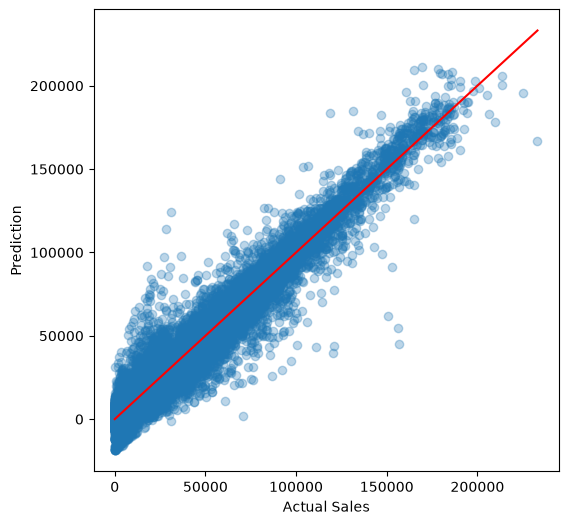

In [36]:
plt.figure(figsize=(6,6))

plt.scatter(y_valid, prediction, alpha=0.3)
plt.xlabel("Actual Sales")
plt.ylabel("Prediction")
plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()],
    color="red"
)

plt.show()

In [37]:
df_encoded.shape

(421570, 29)

##### Random Forest Regression

In [38]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error


rf=RandomForestRegressor(
    n_estimators=100,
    random_state=2026,
    n_jobs= -1
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_valid)


MAE_RF= mean_absolute_error(y_valid, y_pred)
MSE_RF= mean_squared_error(y_valid,y_pred )
RMSE_RF= np.sqrt(mean_squared_error(y_valid, y_pred))
R2_RF= r2_score(y_valid, y_pred)

print("MAE:", MAE_RF)
print("MSE:", MSE_RF)
print("RMSE:", RMSE_RF )
print("R²:", R2_RF )


MAE: 1465.2123824750336
MSE: 10171464.856935235
RMSE: 3189.273405798762
R²: 0.9792057539422696


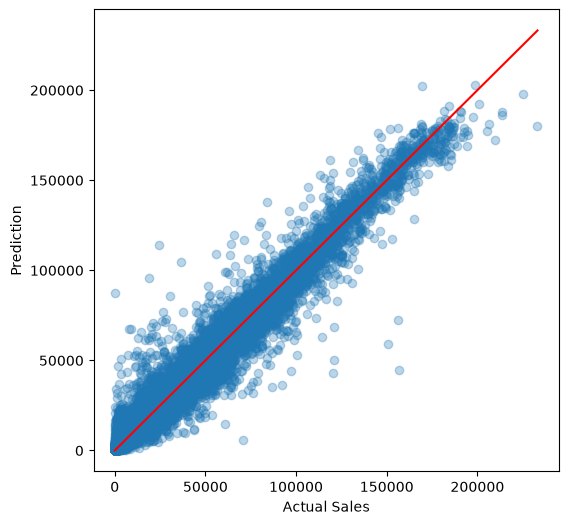

In [39]:
plt.figure(figsize=(6,6))

plt.scatter(y_valid, y_pred, alpha=0.3)
plt.xlabel("Actual Sales")
plt.ylabel("Prediction")
plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()],
    color="red"
)

plt.show()

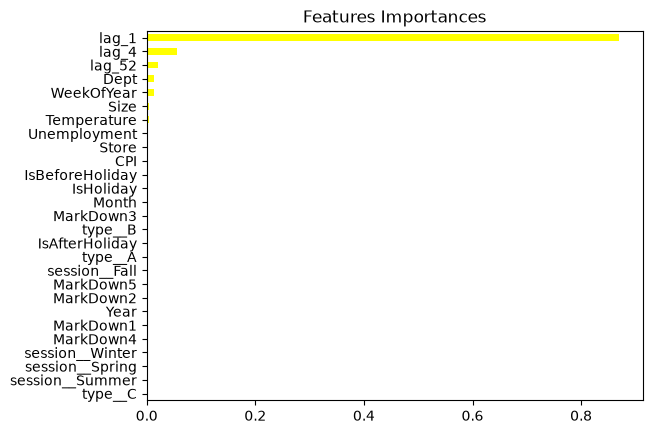

In [40]:
importances_rf=pd.Series(rf.feature_importances_,index= X.columns)
sorted_imp_rf= importances_rf.sort_values()
sorted_imp_rf.plot(kind="barh",color="yellow")
plt.title('Features Importances')
plt.show()

In [41]:
df_encoded.shape

(421570, 29)

In [42]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

rf2 = RandomForestRegressor(random_state=42)


param_dist = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None]
}


random_search = RandomizedSearchCV(
    estimator=rf2,
    param_distributions=param_dist,
    n_iter=10,            
    scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=3),
    random_state=2026,
    n_jobs=4,
    verbose=2
)

random_search.fit(X_train, y_train)

print(random_search.best_params_)
print(random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=50; total time=   3.9s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=50; total time=   9.6s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=50; total time=  16.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=4, min_samples_split=10, n_estimators=200; total time=  17.9s
[CV] END max_depth=None, max_features=None, min_samples_leaf=4, min_samples_split=2, n_estimators=50; total time=  20.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=4, min_samples_split=10, n_estimators=200; total time=  42.4s


/home/hashalike/.local/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=  23.0s
[CV] END max_depth=None, max_features=None, min_samples_leaf=4, min_samples_split=2, n_estimators=50; total time=  56.2s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=4, min_samples_split=10, n_estimators=200; total time= 1.3min
[CV] END max_depth=None, max_features=None, min_samples_leaf=2, min_samples_split=10, n_estimators=50; total time=  21.0s
[CV] END max_depth=None, max_features=log2, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=  53.0s
[CV] END max_depth=None, max_features=None, min_samples_leaf=4, min_samples_split=2, n_estimators=50; total time= 1.7min
[CV] END max_depth=30, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=200; total time=  18.7s
[CV] END max_depth=None, max_features=None, min_samples_leaf=2, min_samples_split=10, n_estimators=50; total time=  56.0s
[CV] END max_depth=None, ma

In [43]:
rf_best_params=RandomForestRegressor(
    n_estimators=200,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    max_depth= 30,
    random_state=2026,
    n_jobs= -1
)

rf_best_params.fit(X_train, y_train)

y_pred = rf_best_params.predict(X_valid)


MAE_RF_Best= mean_absolute_error(y_valid, y_pred)
MSE_RF_Best= mean_squared_error(y_valid,y_pred )
RMSE_RF_Best= np.sqrt(mean_squared_error(y_valid, y_pred))
R2_RF_Best= r2_score(y_valid, y_pred)

print("MAE:", MAE_RF_Best)
print("MSE:", MSE_RF_Best)
print("RMSE:", RMSE_RF_Best)
print("R²:", R2_RF_Best)

MAE: 1380.5736421516635
MSE: 8881556.432218712
RMSE: 2980.194025935008
R²: 0.9818428050998722


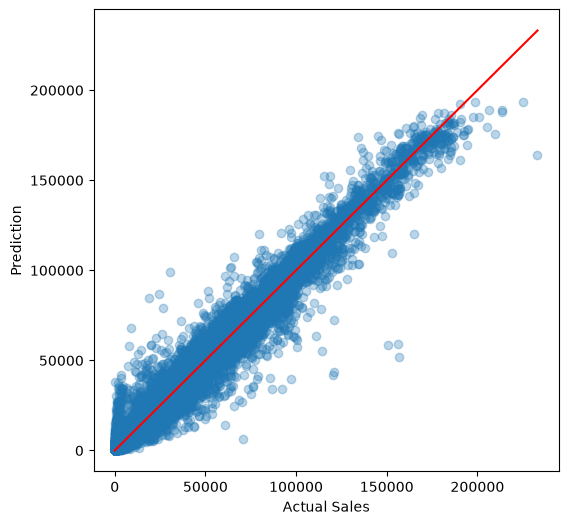

In [44]:
plt.figure(figsize=(6,6))

plt.scatter(y_valid, y_pred, alpha=0.3)
plt.xlabel("Actual Sales")
plt.ylabel("Prediction")
plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()],
    color="red"
)

plt.show()

##### XGBoosting Regression

In [45]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor

model_XGB = XGBRegressor(random_state=2026, n_jobs=1)

params = {
    "n_estimators": [200, 400, 600, 800],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3, 0.5]
}

search = RandomizedSearchCV(
    estimator=model_XGB,
    param_distributions=params,
    n_iter=15,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error",
    random_state=2026,
    n_jobs=4,
    verbose=1
)

search.fit(X_train, y_train)

print(search.best_params_)
print(search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
{'subsample': 0.9, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.5, 'colsample_bytree': 0.9}
-2117.930635829445


In [46]:

best_model = search.best_estimator_

# Tahmin
y_prediction = best_model.predict(X_valid)



MAE_XGB = mean_absolute_error(y_valid, y_prediction)
MSE_XGB= mean_squared_error(y_valid,y_prediction )
RMSE_XGB = np.sqrt(mean_squared_error(y_valid, y_prediction))
R2_XGB = r2_score(y_valid, y_prediction)

print(f"MAE : {MAE_XGB:.2f}")
print(f"MSE: {MSE_XGB:.2f}")
print(f"RMSE: {RMSE_XGB:.2f}")
print(f"R²  : {R2_XGB:.4f}")

MAE : 1475.26
MSE: 9809169.59
RMSE: 3131.96
R²  : 0.9799


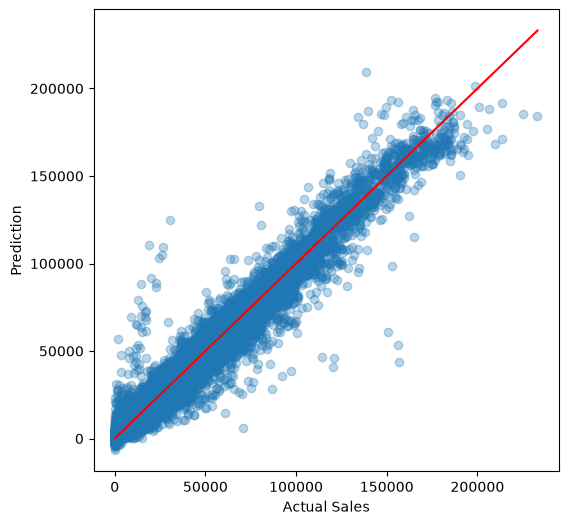

In [47]:
plt.figure(figsize=(6,6))

plt.scatter(y_valid, y_prediction, alpha=0.3)
plt.xlabel("Actual Sales")
plt.ylabel("Prediction")
plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()],
    color="red"
)

plt.show()

#### Model Comparison

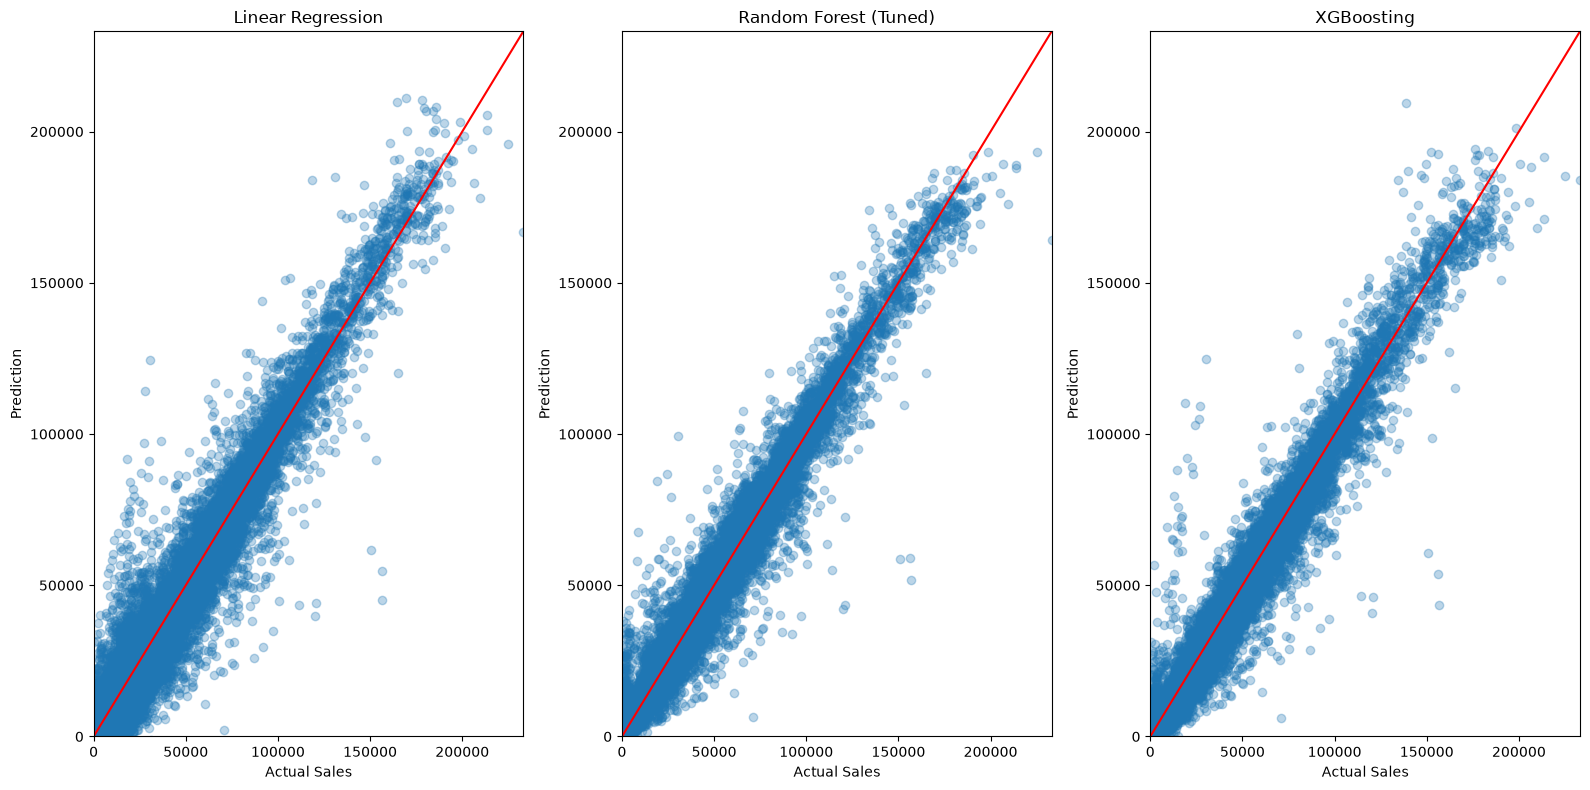

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(16, 8))

# LR
axes[0].scatter(y_valid, prediction, alpha=0.3)
axes[0].plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], color="red")
axes[0].set_xlabel("Actual Sales")
axes[0].set_ylabel("Prediction")
axes[0].set_title("Linear Regression")
axes[0].set_xlim(y_valid.min(), y_valid.max())
axes[0].set_ylim(y_valid.min(), y_valid.max())

# RF (tuned)
axes[1].scatter(y_valid, y_pred, alpha=0.3)
axes[1].plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], color="red")
axes[1].set_xlabel("Actual Sales")
axes[1].set_ylabel("Prediction")
axes[1].set_title("Random Forest (Tuned)")
axes[1].set_xlim(y_valid.min(), y_valid.max())
axes[1].set_ylim(y_valid.min(), y_valid.max())


# XGBoosting
axes[2].scatter(y_valid,y_prediction, alpha=0.3)
axes[2].plot([y_valid.min(),y_valid.max()],[y_valid.min(),y_valid.max()],color="red")
axes[2].set_xlabel("Actual Sales")
axes[2].set_ylabel("Prediction")
axes[2].set_title("XGBoosting")
axes[2].set_xlim(y_valid.min(),y_valid.max())
axes[2].set_ylim(y_valid.min(),y_valid.max())



plt.tight_layout()
plt.show()

In [49]:
features_dict = {
    "MSE": {
        "LR": MSE_LR,
        "RF": MSE_RF_Best,
        "XGB": MSE_XGB
    },
    "RMSE": {
        "LR": RMSE_LR,
        "RF": RMSE_RF_Best,
        "XGB": RMSE_XGB
    },
    "MAE": {
        "LR": MAE_LR,
        "RF": MAE_RF_Best,
        "XGB": MAE_XGB
    },
    "R2": {
        "LR": R2_LR,
        "RF": R2_RF_Best,
        "XGB": R2_XGB
    }
}

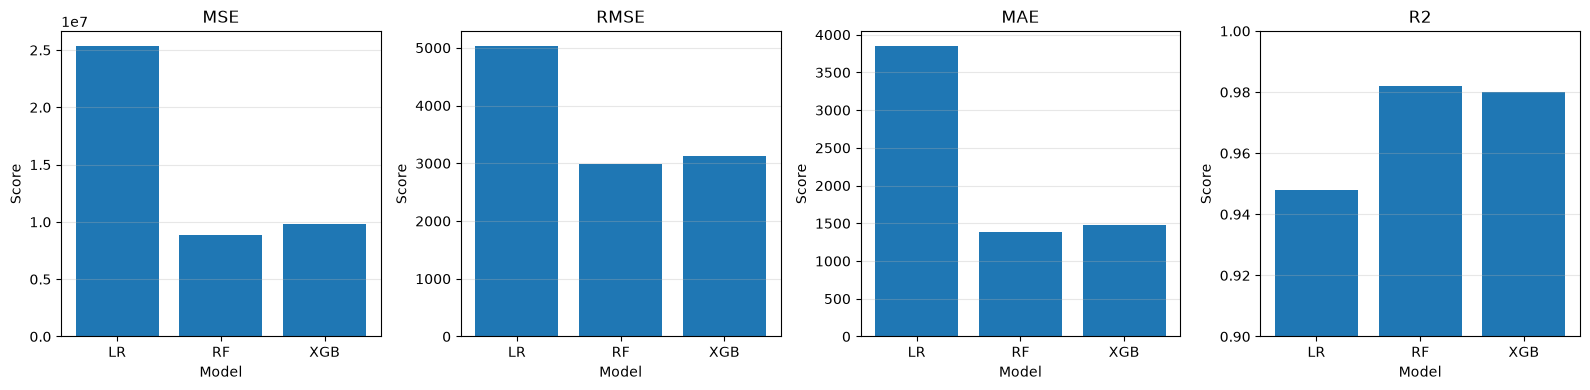

In [50]:
import matplotlib.pyplot as plt

models = ["LR", "RF", "XGB"]
metrics = ["MSE", "RMSE", "MAE", "R2"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, metric in zip(axes, metrics):

    values = [features_dict[metric][model] for model in models]

    ax.bar(models, values)

    ax.set_title(metric)
    ax.set_xlabel("Model")
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.3)

    
plt.ylim(0.9, 1.0)
plt.tight_layout()
plt.show()

In [51]:
DF= pd.DataFrame(features_dict)
print(DF)

              MSE         RMSE          MAE        R2
LR   2.539321e+07  5039.167221  3856.283250  0.948087
RF   8.881556e+06  2980.194026  1380.573642  0.981843
XGB  9.809170e+06  3131.959385  1475.261949  0.979946


#### Prediction using test data

In [52]:
query = """
SELECT t.*, s.Type, s.Size, f.Temperature, f.CPI, f.Unemployment, f.MarkDown1,f.MarkDown2,f.MarkDown3,f.MarkDown4,f.MarkDown5
FROM test AS t
LEFT JOIN stores AS s ON t.Store = s.Store
LEFT JOIN features AS f ON t.Store = f.Store AND t.Date = f.Date;
"""

test_df = pd.read_sql(query, conn)
test_df.head()

,Store,Dept,Date,IsHoliday,Type,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,1,1,2012-11-02,0,A,151315,55.32,223.462779,6.573,6766.44,5147.70,50.82,3639.90,2737.42
1,1,1,2012-11-09,0,A,151315,61.24,223.481307,6.573,11421.32,3370.89,40.28,4646.79,6154.16
2,1,1,2012-11-16,0,A,151315,52.92,223.512911,6.573,9696.28,292.10,103.78,1133.15,6612.69
3,1,1,2012-11-23,1,A,151315,56.23,223.561947,6.573,883.59,4.17,74910.32,209.91,303.32
4,1,1,2012-11-30,0,A,151315,52.34,223.610984,6.573,2460.03,NaN,3838.35,150.57,6966.34


In [53]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         115064 non-null  int64  
 1   Dept          115064 non-null  int64  
 2   Date          115064 non-null  str    
 3   IsHoliday     115064 non-null  int64  
 4   Type          115064 non-null  str    
 5   Size          115064 non-null  int64  
 6   Temperature   115064 non-null  float64
 7   CPI           76902 non-null   float64
 8   Unemployment  76902 non-null   float64
 9   MarkDown1     114915 non-null  float64
 10  MarkDown2     86437 non-null   float64
 11  MarkDown3     105235 non-null  float64
 12  MarkDown4     102176 non-null  float64
 13  MarkDown5     115064 non-null  float64
dtypes: float64(8), int64(4), str(2)
memory usage: 12.3 MB


In [54]:
test_df.describe()

,Store,Dept,IsHoliday,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
count,115064.000000,115064.000000,115064.000000,115064.000000,115064.000000,76902.000000,76902.000000,114915.000000,86437.000000,105235.000000,102176.000000,115064.000000
mean,22.238207,44.339524,0.077592,136497.688921,53.941804,176.961347,6.868733,7689.216439,3734.051729,2403.088666,3356.219071,3922.681189
std,12.809930,30.656410,0.267529,61106.926438,18.724153,41.239967,1.583427,10698.760716,8323.495014,13767.939313,7570.501545,19445.150745
min,1.000000,1.000000,0.000000,34875.000000,-7.290000,131.236226,3.684000,-2781.450000,-35.740000,-179.260000,0.220000,-185.170000
25%,11.000000,18.000000,0.000000,93638.000000,39.820000,138.402033,5.771000,1966.460000,180.350000,15.100000,155.460000,1309.300000
50%,22.000000,37.000000,0.000000,140167.000000,54.470000,192.304445,6.806000,4842.290000,742.590000,78.260000,840.940000,2390.430000
75%,33.000000,74.000000,0.000000,202505.000000,67.350000,223.244532,8.036000,9439.140000,2735.670000,272.580000,3096.920000,4227.270000
max,45.000000,99.000000,1.000000,219622.000000,101.950000,228.976456,10.199000,103184.980000,71074.170000,149483.310000,65344.640000,771448.100000


In [55]:
test_df.isna().sum()

Store               0
Dept                0
Date                0
IsHoliday           0
Type                0
Size                0
Temperature         0
CPI             38162
Unemployment    38162
MarkDown1         149
MarkDown2       28627
MarkDown3        9829
MarkDown4       12888
MarkDown5           0
dtype: int64

In [56]:
test_df["Date"]= pd.to_datetime(test_df["Date"],format= "%Y-%m-%d",errors="coerce")
test_df["IsHoliday"]=test_df["IsHoliday"].astype("category")
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         115064 non-null  int64         
 1   Dept          115064 non-null  int64         
 2   Date          115064 non-null  datetime64[us]
 3   IsHoliday     115064 non-null  category      
 4   Type          115064 non-null  str           
 5   Size          115064 non-null  int64         
 6   Temperature   115064 non-null  float64       
 7   CPI           76902 non-null   float64       
 8   Unemployment  76902 non-null   float64       
 9   MarkDown1     114915 non-null  float64       
 10  MarkDown2     86437 non-null   float64       
 11  MarkDown3     105235 non-null  float64       
 12  MarkDown4     102176 non-null  float64       
 13  MarkDown5     115064 non-null  float64       
dtypes: category(1), datetime64[us](1), float64(8), int64(3), str(1)
memory usage: 1

In [57]:
markdown_test= ["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]


test_df[markdown_test]=test_df[markdown_test].fillna(0)
test_df.isna().sum()

Store               0
Dept                0
Date                0
IsHoliday           0
Type                0
Size                0
Temperature         0
CPI             38162
Unemployment    38162
MarkDown1           0
MarkDown2           0
MarkDown3           0
MarkDown4           0
MarkDown5           0
dtype: int64

In [58]:
test_sorted= test_df.sort_values(by="Date")
test_sorted[["CPI", "Unemployment"]] = test_sorted.groupby("Store")[["CPI","Unemployment"]].ffill()
test_sorted.head()

,Store,Dept,Date,IsHoliday,Type,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,1,1,2012-11-02,0,A,151315,55.32,223.462779,6.573,6766.44,5147.70,50.82,3639.90,2737.42
48640,19,10,2012-11-02,0,A,203819,46.81,138.622710,7.992,11686.96,18053.48,88.94,5484.50,3833.76
42002,16,55,2012-11-02,0,B,57197,38.20,199.290867,5.847,2826.02,984.41,4.46,274.18,1411.99
57105,22,18,2012-11-02,0,B,119557,54.55,142.661460,7.543,8793.36,10347.53,5.62,7350.89,801.32
65138,25,16,2012-11-02,0,B,128107,40.83,216.156711,7.293,12435.08,16493.02,55.19,1165.36,1144.39


In [59]:
test_sorted.isna().sum()

Store           0
Dept            0
Date            0
IsHoliday       0
Type            0
Size            0
Temperature     0
CPI             0
Unemployment    0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
dtype: int64

In [60]:
test_sorted["Year"]=test_sorted["Date"].dt.year 
test_sorted["Month"]= test_sorted["Date"].dt.month 
test_sorted["WeekOfYear"]= test_sorted["Date"].dt.isocalendar().week

In [61]:
conditions= [
    test_sorted["Month"].isin([12,1,2]),
    test_sorted["Month"].isin([3,4,5]),
    test_sorted["Month"].isin([6,7,8]),
]

choices= ["Winter","Spring","Summer"]

test_sorted["Session"]= np.select(conditions,choices,default="Fall")
test_sorted.head()

,Store,Dept,Date,IsHoliday,Type,Size,Temperature,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,Year,Month,WeekOfYear,Session
0,1,1,2012-11-02,0,A,151315,55.32,223.462779,6.573,6766.44,5147.70,50.82,3639.90,2737.42,2012,11,44,Fall
48640,19,10,2012-11-02,0,A,203819,46.81,138.622710,7.992,11686.96,18053.48,88.94,5484.50,3833.76,2012,11,44,Fall
42002,16,55,2012-11-02,0,B,57197,38.20,199.290867,5.847,2826.02,984.41,4.46,274.18,1411.99,2012,11,44,Fall
57105,22,18,2012-11-02,0,B,119557,54.55,142.661460,7.543,8793.36,10347.53,5.62,7350.89,801.32,2012,11,44,Fall
65138,25,16,2012-11-02,0,B,128107,40.83,216.156711,7.293,12435.08,16493.02,55.19,1165.36,1144.39,2012,11,44,Fall


In [62]:
test_encoded= pd.get_dummies(test_sorted, columns=["Type","Session"], dtype=int, prefix=["type_","session_"])

In [63]:
test_encoded.columns

Index(['Store', 'Dept', 'Date', 'IsHoliday', 'Size', 'Temperature', 'CPI',
       'Unemployment', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4',
       'MarkDown5', 'Year', 'Month', 'WeekOfYear', 'type__A', 'type__B',
       'type__C', 'session__Fall', 'session__Spring', 'session__Summer',
       'session__Winter'],
      dtype='str')

In [64]:
df.columns

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Type', 'Size',
       'Temperature', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2',
       'MarkDown3', 'MarkDown4', 'MarkDown5', 'Year', 'Month', 'WeekOfYear',
       'Session', 'lag_1', 'lag_4', 'lag_52', 'IsBeforeHoliday',
       'IsAfterHoliday'],
      dtype='str')

In [65]:
walmart_df= pd.concat([df, test_encoded], ignore_index= True)
walmart_df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,...,lag_52,IsBeforeHoliday,IsAfterHoliday,type__A,type__B,type__C,session__Fall,session__Spring,session__Summer,session__Winter
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,211.096358,8.106,...,0.0,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,211.242170,8.106,...,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,211.289143,8.106,...,0.0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,211.319643,8.106,...,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,211.350143,8.106,...,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [66]:
walmart_df.shape


(536634, 31)

In [67]:
walmart_df.isna().sum()

Store                   0
Dept                    0
Date                    0
Weekly_Sales       115064
IsHoliday               0
Type               115064
Size                    0
Temperature             0
CPI                     0
Unemployment            0
MarkDown1               0
MarkDown2               0
MarkDown3               0
MarkDown4               0
MarkDown5               0
Year                    0
Month                   0
WeekOfYear              0
Session            115064
lag_1              115064
lag_4              115064
lag_52             115064
IsBeforeHoliday    115064
IsAfterHoliday     115064
type__A            421570
type__B            421570
type__C            421570
session__Fall      421570
session__Spring    421570
session__Summer    421570
session__Winter    421570
dtype: int64

In [68]:
walmart_sorted= walmart_df.sort_values(by="Date")
walmart_df["lag_1"]= walmart_sorted.groupby(["Store","Dept"])["Weekly_Sales"].shift(1)
walmart_df["lag_4"]=walmart_sorted.groupby(["Store","Dept"])["Weekly_Sales"].shift(4)
walmart_df["lag_52"]= walmart_sorted.groupby(["Store","Dept"])["Weekly_Sales"].shift(52)


walmart_df["lag_1"]=walmart_df["lag_1"].fillna(0)
walmart_df["lag_4"]=walmart_df["lag_4"].fillna(0)
walmart_df["lag_52"]= walmart_df["lag_52"].fillna(0)


In [69]:
walmart_df[["lag_1","lag_4","lag_52"]].isna().sum()

lag_1     0
lag_4     0
lag_52    0
dtype: int64

In [70]:
walmart_df["IsBeforeHoliday"]= walmart_sorted.groupby(["Store","Dept"])["IsHoliday"].shift(-1)
walmart_df["IsBeforeHoliday"]=walmart_df["IsBeforeHoliday"].fillna(0)
walmart_df["IsBeforeHoliday"].isna().sum()

np.int64(0)

In [71]:
print(walmart_df["IsBeforeHoliday"].value_counts())
print(walmart_df["IsHoliday"].value_counts())

IsBeforeHoliday
0    498132
1     38502
Name: count, dtype: int64
IsHoliday
0    498045
1     38589
Name: count, dtype: int64


In [72]:
walmart_df["IsAfterHoliday"]= walmart_sorted.groupby(["Store","Dept"])["IsHoliday"].shift(1)
walmart_df["IsAfterHoliday"]=walmart_df["IsAfterHoliday"].fillna(0)
walmart_df["IsAfterHoliday"].isna().sum()

np.int64(0)

In [73]:
walmart_df.isna().sum()

Store                   0
Dept                    0
Date                    0
Weekly_Sales       115064
IsHoliday               0
Type               115064
Size                    0
Temperature             0
CPI                     0
Unemployment            0
MarkDown1               0
MarkDown2               0
MarkDown3               0
MarkDown4               0
MarkDown5               0
Year                    0
Month                   0
WeekOfYear              0
Session            115064
lag_1                   0
lag_4                   0
lag_52                  0
IsBeforeHoliday         0
IsAfterHoliday          0
type__A            421570
type__B            421570
type__C            421570
session__Fall      421570
session__Spring    421570
session__Summer    421570
session__Winter    421570
dtype: int64

In [ ]:
train_final = walmart_df[walmart_df["Weekly_Sales"].notna()]
test_final = walmart_df[walmart_df["Weekly_Sales"].isna()]

print(train_final.shape)  
print(test_final.shape)   

(421570, 31)
(115064, 31)


In [75]:
X_train_final= train_final[['Store', 'Dept','IsHoliday', 'Size',
       'Temperature', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2',
       'MarkDown3', 'MarkDown4', 'MarkDown5', 'Year', 'Month', 'WeekOfYear',
        'lag_1','lag_4', 'lag_52', 'IsBeforeHoliday',
       'IsAfterHoliday', 'type__A', 'type__B', 'type__C','session__Fall', 'session__Spring',
       'session__Summer', 'session__Winter']]



y_train_final= train_final["Weekly_Sales"]



X_test_final= test_final[['Store', 'Dept','IsHoliday', 'Size',
       'Temperature', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2',
       'MarkDown3', 'MarkDown4', 'MarkDown5', 'Year', 'Month', 'WeekOfYear',
        'lag_1','lag_4', 'lag_52', 'IsBeforeHoliday',
       'IsAfterHoliday', 'type__A', 'type__B', 'type__C','session__Fall', 'session__Spring',
       'session__Summer', 'session__Winter']]


In [76]:
print(X_train_final.shape)
print(X_test_final.shape)
print(list(X_train_final.columns) == list(X_test_final.columns))

(421570, 27)
(115064, 27)
True


In [77]:
final_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    max_depth=30,
    random_state=2026,
    n_jobs=-1
)

final_model.fit(X_train_final, y_train_final)


test_predictions = final_model.predict(X_test_final)

In [78]:
test_final['Predicted_Sales'] = test_predictions
test_final.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,CPI,Unemployment,...,IsBeforeHoliday,IsAfterHoliday,type__A,type__B,type__C,session__Fall,session__Spring,session__Summer,session__Winter,Predicted_Sales
421570,1,1,2012-11-02,NaN,0,NaN,151315,55.32,223.462779,6.573,...,0,0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,34374.437906
421571,19,10,2012-11-02,NaN,0,NaN,203819,46.81,138.622710,7.992,...,0,0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,30669.916478
421572,16,55,2012-11-02,NaN,0,NaN,57197,38.20,199.290867,5.847,...,0,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,5376.784431
421573,22,18,2012-11-02,NaN,0,NaN,119557,54.55,142.661460,7.543,...,0,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,17953.739107
421574,25,16,2012-11-02,NaN,0,NaN,128107,40.83,216.156711,7.293,...,0,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,4762.222372


In [79]:
test_sales= test_final.groupby('Date')['Predicted_Sales'].sum()
test_sales.head()

Date
2012-11-02    4.834563e+07
2012-11-09    2.764969e+07
2012-11-16    2.727117e+07
2012-11-23    4.290229e+07
2012-11-30    1.667721e+07
Name: Predicted_Sales, dtype: float64

In [80]:
test_final[test_final['Date'] == '2012-11-02'][['Store','Dept','lag_1','lag_4','lag_52','Predicted_Sales']].sort_values('Predicted_Sales', ascending=False).head(10)

,Store,Dept,lag_1,lag_4,lag_52,Predicted_Sales
423620,20,92,160785.98,187027.05,186064.73,188013.571469
424483,13,92,183483.92,181471.61,181936.16,186817.099826
421879,2,92,169784.13,192860.85,173785.31,183251.067634
424185,14,92,164464.02,169519.23,208504.83,182210.214375
423090,4,92,164891.82,186274.98,179147.18,180541.018936
421781,1,92,132155.74,159459.88,152401.64,152768.512788
422906,4,95,145803.47,157750.68,146342.91,150825.461782
423563,20,95,141644.44,154324.26,139008.08,146316.441297
424133,27,92,156059.63,141883.37,141555.97,144065.405731
422128,24,92,134136.75,150026.37,135444.72,141569.806306


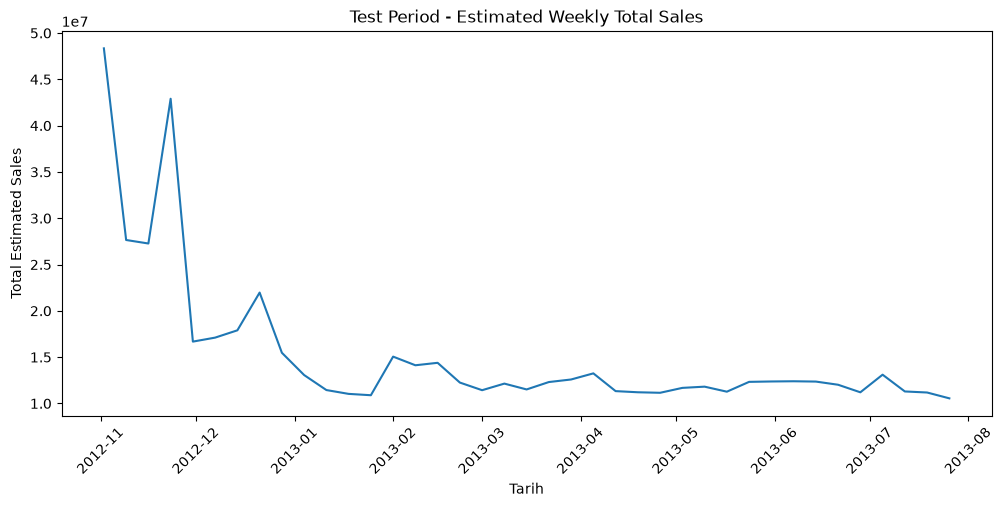

In [81]:
plt.figure(figsize=(12, 5))
plt.plot(test_sales.index, test_sales.values)
plt.xlabel("Tarih")
plt.ylabel("Total Estimated Sales")
plt.title("Test Period - Estimated Weekly Total Sales")
plt.xticks(rotation=45)
plt.show()